# Comparaison AE vs PCA 

In [43]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from sklearn.decomposition import PCA

SEED = 0  # uniquement pour la projection 2D (visualisation)

pd.set_option("display.width", 200)

repertoire = os.getcwd()
REP_DIR = os.path.dirname(repertoire) # revenir à la racine du projet 
print(REP_DIR)
DATA_DIR = f"{REP_DIR}/data"
RESULTATS = f"{repertoire}/results"

print(f"datas : {DATA_DIR}")
print(f"résultats : {RESULTATS}")

/autofs/unitytravail/travail/smundel/M2/analyse_entrepot/projet_DEA/projet_DEA
datas : /autofs/unitytravail/travail/smundel/M2/analyse_entrepot/projet_DEA/projet_DEA/data
résultats : /autofs/unitytravail/travail/smundel/M2/analyse_entrepot/projet_DEA/projet_DEA/Scripts/results


In [ ]:
def charger_npz(chemin):
    return np.load(chemin, allow_pickle=True)

res_PCA = f"{RESULTATS}/resultats_PCA.npz"
res_AE = f"{RESULTATS}/resultats_AE.npz"
pca = charger_npz(res_PCA)
ae = charger_npz(res_AE)

# --- Résultats PCA ---------------------------------------------------------
Z_pca_train, Z_pca_val = pca["Z_train"], pca["Z_val"]
mse_pca_train, mse_pca_val = float(pca["mse_train"]), float(pca["mse_val"])

# --- Résultats AE simple et AE profond ------------------------------------
Z_ae_train, Z_ae_val = ae["Z_train"], ae["Z_val"]
mse_ae_train, mse_ae_val = float(ae["mse_train"]), float(ae["mse_val"])

Z_ae_profond_train = ae["Z_train_profond"]
Z_ae_profond_val = ae["Z_val_profond"]
mse_ae_profond_train = float(ae["mse_train_profond"])
mse_ae_profond_val = float(ae["mse_val_profond"])

# --- Contrôle de la dimension de représentation ---------------------------
dimensions = {
    "PCA": Z_pca_train.shape[1],
    "AE simple": Z_ae_train.shape[1],
    "AE profond": Z_ae_profond_train.shape[1],
}
D = dimensions["PCA"]
print(f"dimension de représentation : {D}")

# --- Données et labels ----------------------------------------------------
train = sc.read_h5ad(f"{DATA_DIR}/train.h5ad")
val = sc.read_h5ad(f"{DATA_DIR}/val.h5ad")

X_train = train.X.toarray() if sp.issparse(train.X) else np.asarray(train.X)
X_val = val.X.toarray() if sp.issparse(val.X) else np.asarray(val.X)

# La référence ne doit voir que le train
moyenne_train = X_train.mean(axis=0, dtype=np.float64)
mse_ref_train = float(np.mean((X_train - moyenne_train) ** 2)) # MSE = Mean Squared Error
mse_ref_val = float(np.mean((X_val - moyenne_train) ** 2))

print(f"train : {X_train.shape} | validation : {X_val.shape}")
print(
    "référence (moyenne par gène) : "
    f"MSE train {mse_ref_train:.4f} | validation {mse_ref_val:.4f}"
)

dimension de représentation : 50
train : (13105, 2000) | validation : (3277, 2000)
référence (moyenne par gène) : MSE train 0.1883 | validation 0.1887


## 1. Comparaison des erreurs de reconstruction

Toutes les MSE sont calculées sur la **même matrice cible** (2 000 gènes)

Comparer la MSE : PCA, autoencodeur simple et autoencodeur profond --> peut reconstruire les données d’expression des gènes à partir d’une représentation réduite à 50 dimensions.

La MSE est la moyenne des erreurs au carré entre les valeurs originales et reconstruites : plus elle est basse, meilleure est la reconstruction. Les MSE de validation permettent de comparer les méthodes sur des données non utilisées pour l’apprentissage, tandis que la comparaison avec la référence « moyenne par gène » vérifie qu’elles font mieux qu’une prédiction très simple.
La référence, c’est un modèle très simple qui prédit, pour chaque gène, sa moyenne calculée sur les cellules du jeu d’entraînement. Il ne tient donc pas compte des différences entre les cellules.


In [75]:
comparaison = pd.DataFrame(
    {
        "MSE train": [mse_ref_train, mse_pca_train, mse_ae_train, mse_ae_profond_train],
        "MSE validation": [mse_ref_val, mse_pca_val, mse_ae_val, mse_ae_profond_val],
    },
    index=[
        "Moyenne par gène (référence)",
        f"PCA ({D} composantes)",
        f"AE simple (latent {D})",
        f"AE profond (latent {D})",
    ],
)

print(comparaison["MSE validation"])
mse_ref, mse_pca, mse_ae, mse_aep = comparaison["MSE validation"]
print()
for nom, mse in [
    (f"PCA", mse_pca),
    (f"AE simple", mse_ae),
    (f"AE profond",mse_aep)
]:
    gain = 100 * (1 - mse / mse_ref)
    print(f"{nom} : MSE validation = {mse:.4f} ({gain:+.1f} % par rapport à la référence {mse_ref:.4f})")
print("Plus le MSE est bas, meilleure est la reconstruction")

Moyenne par gène (référence)    0.188715
PCA (50 composantes)            0.072067
AE simple (latent 50)           0.073273
AE profond (latent 50)          0.069263
Name: MSE validation, dtype: float64

PCA : MSE validation = 0.0721 (+61.8 % par rapport à la référence 0.1887)
AE simple : MSE validation = 0.0733 (+61.2 % par rapport à la référence 0.1887)
AE profond : MSE validation = 0.0693 (+63.3 % par rapport à la référence 0.1887)
Plus le MSE est bas, meilleure est la reconstruction


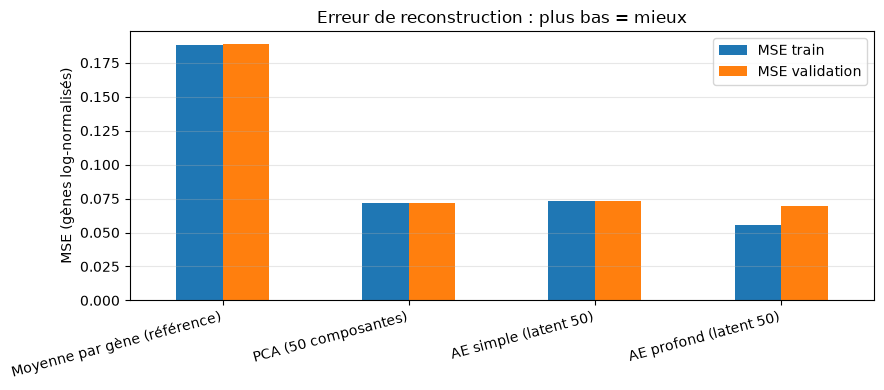

In [49]:
ax = comparaison[["MSE train", "MSE validation"]].plot.bar(figsize=(9, 4))
ax.set_ylabel("MSE (gènes log-normalisés)")
ax.set_xlabel("")
ax.set_title("Erreur de reconstruction : plus bas = mieux")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 2. Les représentations en 2D

Même dimension ne veut pas dire même qualité de représentation : on projette chaque latent de **train** en 2D par une PCA, et on colorie par type cellulaire. Les structures qui apparaissent sont celles que le clustering pourra exploiter.

Chaque panneau a sa propre projection : les axes ne sont pas comparables d'un panneau à l'autre, seule la séparation des types cellulaires l'est. Les latents sont réordonnés sur `train.obs_names` avant l'affichage : si les résultats et le fichier `.h5ad` ne proviennent pas du même découpage, le notebook s'arrête au lieu d'afficher des couleurs fausses.

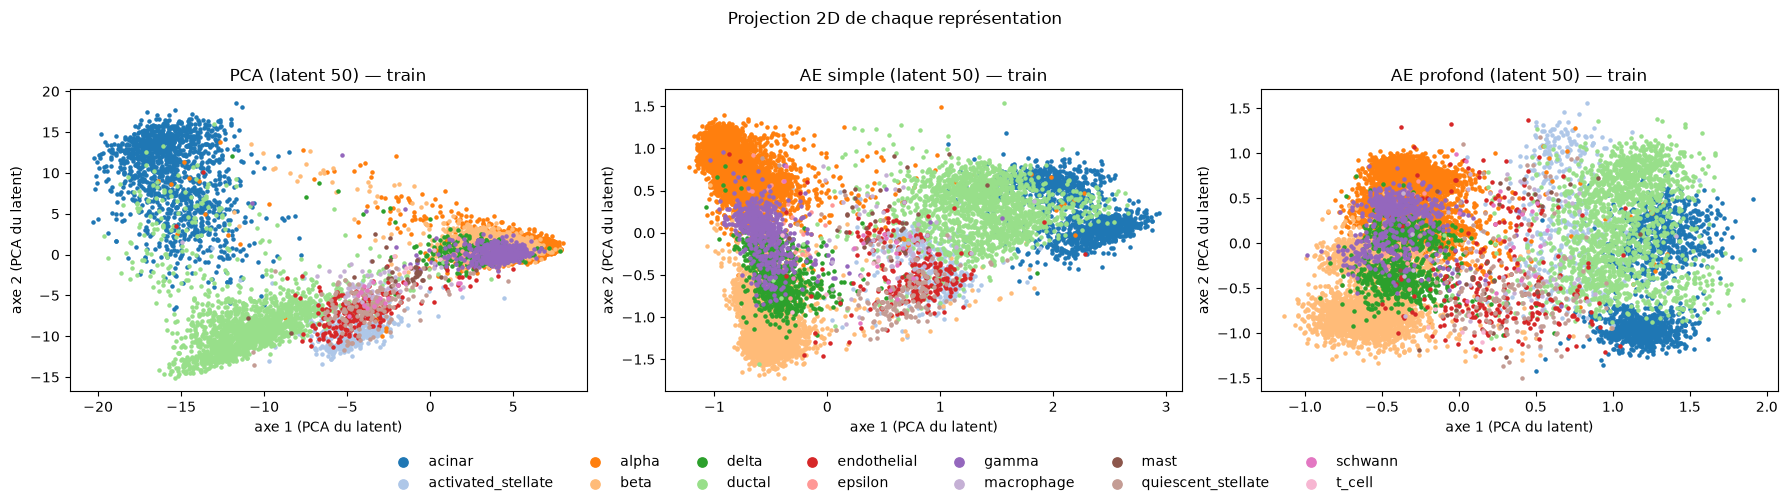

In [52]:
def ordonner(Z, noms_sauvegardes, noms_cibles):
    """Réordonne Z selon les noms des cellules."""
    noms = pd.Index(np.asarray(noms_sauvegardes, dtype=str))
    ordre = noms.get_indexer(noms_cibles)
    if (ordre < 0).any():
        raise ValueError("Les cellules des résultats et du train ne coïncident pas.")
    return Z[ordre]


labels = train.obs["celltype"].astype("category")
codes = labels.cat.codes.to_numpy()
categories = list(labels.cat.categories)

representations = [
    ("PCA", ordonner(Z_pca_train, pca["train_obs_names"], train.obs_names)),
    ("AE simple", ordonner(Z_ae_train, ae["train_obs_names"], train.obs_names)),
    ("AE profond", ordonner(Z_ae_profond_train, ae["train_obs_names"], train.obs_names)),
]

palette = plt.get_cmap("tab20")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (nom, Z) in enumerate(representations):
    ax = axes[i]
    Z_2d = PCA(n_components=2, random_state=SEED).fit_transform(Z)
    for code, categorie in enumerate(categories):
        masque = codes == code
        ax.scatter(
            Z_2d[masque, 0],
            Z_2d[masque, 1],
            s=5,
            color=palette(code % 20),
            label=categorie,
        )
    ax.set_title(f"{nom} (latent {D}) — train")
    ax.set_xlabel("axe 1 (PCA du latent)")
    ax.set_ylabel("axe 2 (PCA du latent)")

poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(
    poignees,
    etiquettes,
    loc="lower center",
    ncol=7,
    markerscale=3,
    frameon=False,
)
fig.suptitle("Projection 2D de chaque représentation")
fig.tight_layout(rect=(0, 0.10, 1, 0.96))
plt.show()

## Objectif 
Convaincre à quel point le modèle est bon ou a quel point il est mauvais 
Problème de déonthologie 
Faire un petit story-telling, Raconter l'histoire finale (logique de toutes ces étapes --> on est parti de la et on arrive à ça) 
Certaines classes majoritairement prédites, ...
Analyse statistiques --> pourquoi une classe ça va pas, pourquoi moins prédites, ... 
Jouer sur la loss en plus de l'architecture par exemple 
Quand données osus-representer, modèle prédise moins bien --> prendre en compte le déséquilibre dans la loss

Faire une forward pass dans l'AE 
Appliqué algo de clustering dans l'esapce latent 

Accuracy --> vérité terrain obligatoire 

Modèle = projection + clustering 
Envoie données dedans et essayer de comprendre le modèle 
Utilisant outil d'enrichissement de cluster de gène --> GO, ...
Evalusation --> Qualité de l'analyse des performances. Plus interessant est de savoir a quelle point on est capable d'avoir un esprit critique en analysant les performances du modèle

Chercher à savoir si le modèle est bon sur tout les types cellulaires ? 
Autant de clsuter que de type cellulire.
Objectif d'avoir toutes les cellules d'un type dans le même cluster 

Justifié pourquoi faire une PCA (mathématiquement fondé comparer à l'AE)
Si PCA meilleur que AE, ne surtout pas utiliser l'AE
PCA + clustering
AE + clustering 

FAIRE UN NOTEBOOK POUR L'ENTRAINEMENT DE L'AE
Si cluster marche mais pas AE --> problématique car pas savoir gérer les données d'entrées 

Utiliser pluseurs méthodes de projection : Tisny, UMAP 

CLuster : Projeter espace latent et mettre des couleurs en fonction des types dans el cluster 